# 2.2 · Reconstructing the FTSE All-Share from our own data

Notebook 2.1 rebuilt the S&P 500 from our own constituents, prices, dividends and share counts. This notebook does the
same for London: the **FTSE All-Share**, the index behind the UK universe of the later notebooks.

The FTSE All-Share is not one list but the union of three disjoint size segments of the London main market:

| Index | Members | What it is |
|---|---|---|
| **FTSE 100** | ~100 | the largest companies |
| **FTSE 250** | ~250 | the next 250 (the "mid caps") |
| **FTSE SmallCap** | ~175-400 | the rest that pass FTSE's size and liquidity screens |

Together they cover roughly 98 % of the UK market's capitalisation. A company moves between the segments at FTSE's
quarterly reviews (March, June, September, December), so a company can leave the FTSE 100 and still be in the
All-Share.

**Weighting.** FTSE weights each constituent by its **free-float market capitalisation**,
$w_i = \frac{P_i S_i f_i}{\sum_j P_j S_j f_j}$, where $S_i$ is shares in issue and $f_i$ the investable fraction
(excluding strategic holdings such as founders', governments' and cross-holdings). We use LSEG's free-float share count
for each listing, updated monthly.

**Currency.** Everything is in pounds. London prices are quoted in pence (GBX) and are divided by 100; the few members
quoted in dollars or euros (Coca-Cola Europacific, some miners) are converted at the day's exchange rate; dividends
declared in dollars (Shell, HSBC) are converted too.

The comparisons (LSEG's index levels):

| RIC | Description | Includes dividends? |
|---|---|---|
| `.FTASXGBPT` | FTSE All-Share **total return** | yes - gross dividends reinvested on the ex-date |
| `.FTSE` | FTSE 100 price index | no |
| `.FTMC` | FTSE 250 price index | no |
| `.FTSC` | FTSE SmallCap price index | no |

The official indices include **investment trusts** (closed-end funds listed in London: a portfolio of other assets,
not an operating company). So does the reconstruction here, until step 5, which removes them as the research universe
does.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.research import indices as ix
from equity_research.research.cache import ResearchCache

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
TODAY = pd.Timestamp.today().strftime("%Y-%m-%d")

START = "2006-01-01"  # LSEG's official closing prices for London reach back to 2006
SEGMENTS = {"FTSE100": ".FTSE", "FTSE250": ".FTMC", "FTSESC": ".FTSC"}  # our index code -> LSEG's level
NAMES = {"FTSE100": "FTSE 100", "FTSE250": "FTSE 250", "FTSESC": "FTSE SmallCap"}
allshare = ix.load_index_data(cache, "FTSEAS", START, TODAY)
today = allshare.segment.iloc[-1].value_counts()
print(
    f"{allshare.close.shape[1]:,} London listings have been in the FTSE All-Share since {START}; "
    f"{int(allshare.members.iloc[-1].sum())} are in it today: {today.to_dict()}"
)

1,320 London listings have been in the FTSE All-Share since 2006-01-01; 526 are in it today: {'FTSE250': 251, 'FTSESC': 174, 'FTSE100': 101}


## Step 1 · Constituents and their market capitalisation

Market capitalisation = price × free-float shares. A free-float count is in the shares of the date it was published,
so a split or consolidation after that date rescales it (a 1-for-10 consolidation divides it by ten from the ex-date).

The chart shows the fraction of each day's constituents we can value - a price, a return and a share count. A
constituent we cannot value is left out that day and its weight shared pro rata among the others.

Share counts used today: {'float': 526}


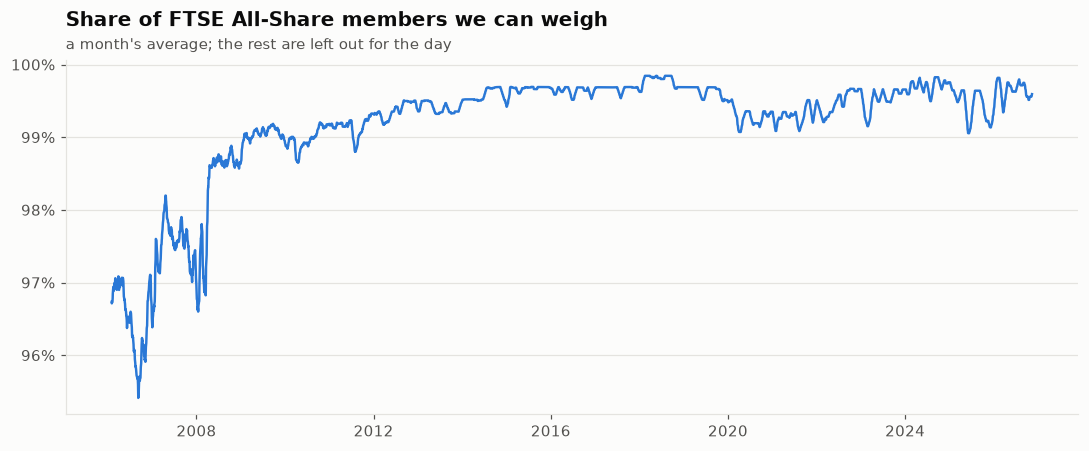

In [2]:
cap = ix.cap_weighted(allshare.price_returns, allshare.market_cap, allshare.members)
source = allshare.share_source.where(allshare.members).iloc[-1].value_counts()
print("Share counts used today:", source.to_dict())
fig = charts.lines(
    {"members we can value": cap["covered"].rolling(21).mean()},
    "Share of FTSE All-Share members we can weigh",
    subtitle="a month's average; the rest are left out for the day",
    percent=True,
)

The ten largest weights today. The FTSE All-Share is top-heavy: a handful of multinationals dominate it - Shell,
HSBC and AstraZeneca each weigh 7 to 8 % - and the FTSE 100's ~100 companies are most of its value, the ~175 SmallCap
companies only about 1 %.

Together the ten weigh 43% of the index.
Weight of each segment: {'FTSE 100': '88.2%', 'FTSE 250': '10.6%', 'FTSE SmallCap': '1.2%'}


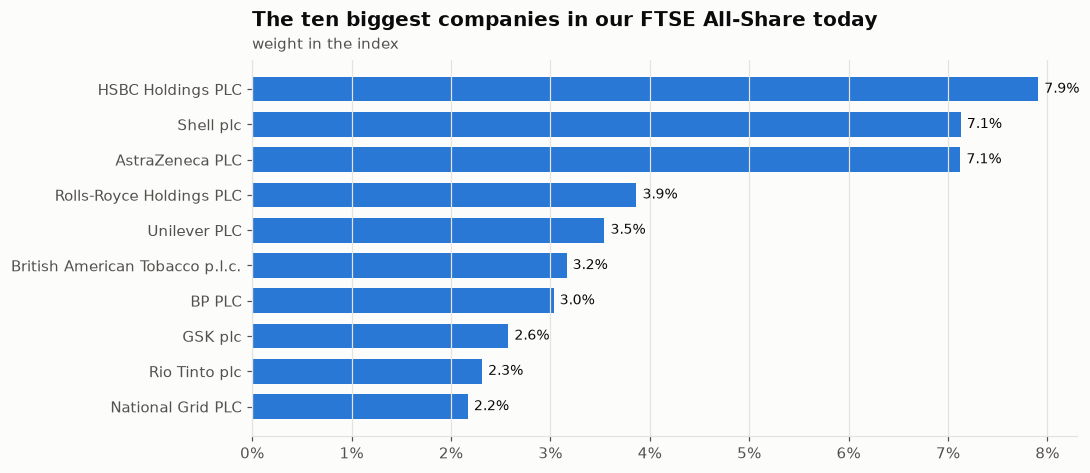

In [3]:
latest = allshare.market_cap.iloc[-1].where(allshare.members.iloc[-1]).dropna()
weights = (latest / latest.sum()).sort_values(ascending=False)
top = weights.head(10).rename(index=allshare.names)
fig = charts.ranked_bars(
    top, "The ten biggest companies in our FTSE All-Share today", subtitle="weight in the index", percent=True
)
by_segment = weights.groupby(allshare.segment.iloc[-1]).sum().reindex(list(SEGMENTS))
print(f"Together the ten weigh {top.sum():.0%} of the index.")
print("Weight of each segment:", {NAMES[k]: f"{v:.1%}" for k, v in by_segment.items()})

## Step 2 · Cap-weighted reconstruction against the FTSE All-Share

Each day the portfolio return is $r_{p,t} = \sum_i w_{i,t-1}\, r_{i,t}$, with weights from the previous close's
market capitalisations - exactly what an index-tracking fund earns before costs. The official level is a **total
return** index, so we include dividends: a member's return on its ex-dividend day is
$(P_t + D_t)/P_{t-1} - 1$.

Two statistics summarise the fit:

* **Tracking error** - the annualised standard deviation of the daily return difference,
  $\sigma(r_p - r_b)\sqrt{252}$. A tracking error of 1 % means the two typically end a year within about 1 % of each
  other.
* **Correlation** of daily returns - close to 1 means they move together day by day.

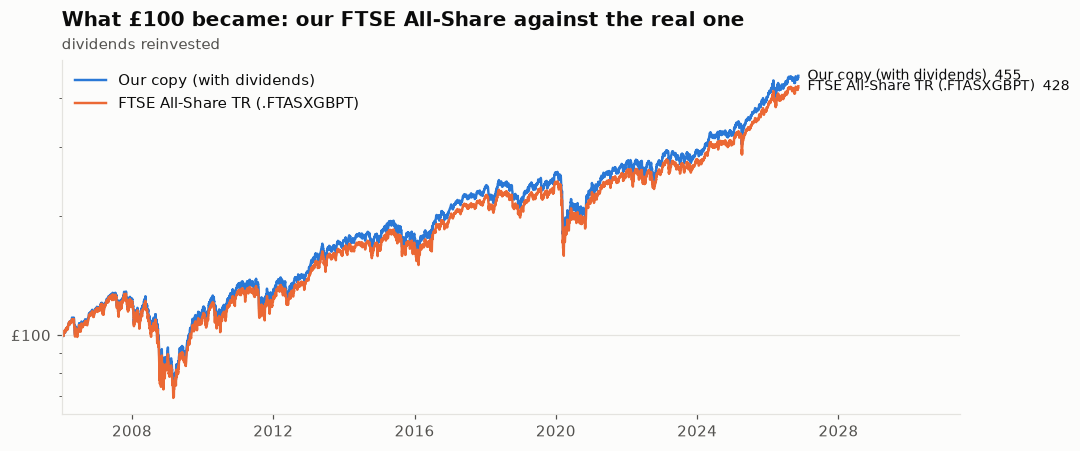

In [4]:
cap_tr = ix.cap_weighted(allshare.total_returns, allshare.market_cap, allshare.members)
ftas = ix.vendor_returns(cache, ".FTASXGBPT", total=False, id_type="RIC")  # the level already includes dividends
fig = charts.growth(
    {"Our copy (with dividends)": cap_tr["return"], "FTSE All-Share TR (.FTASXGBPT)": ftas},
    "What £100 became: our FTSE All-Share against the real one",
    subtitle="dividends reinvested",
    symbol="£",
)

## Step 3 · The three segments, prices only

Rebuilding each segment on its own is a sharper test: an error in a small company is lost in the All-Share (where
the FTSE 100 dominates) but shows in the FTSE SmallCap.

The membership history comes from LSEG's lists of each index's joiners and leavers since 2005, replayed backwards from
today's members. Those lists are incomplete in the early years: a leaver with no matching joiner would be taken to have
been a member since 2005, which left 180 companies in two segments at once (3i Group in both the FTSE 100 and the
SmallCap from 2005 to 2009). The three segments never share a member, so the loader keeps the dates the events give
and moves the inferred ones to fit them - 3i left the SmallCap's history altogether, Enterprise Inns went from the
FTSE 100 (until September 2008) to the 250 and then the SmallCap (September 2011). A move neither event dates is put
halfway: Computacenter joined the FTSE 250 in 2009 and is in the FTSE 100 today, with no record of when it moved.
`allshare.segment` names each member's segment on each day.

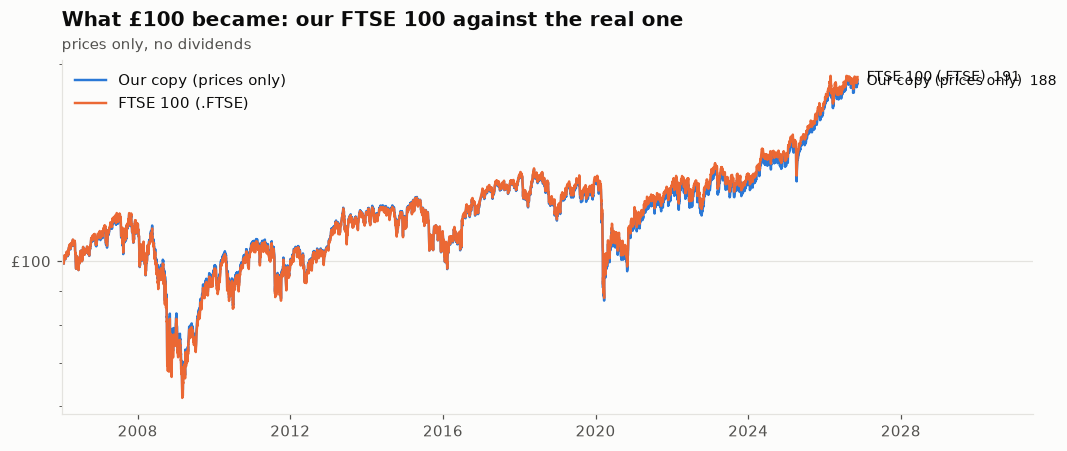

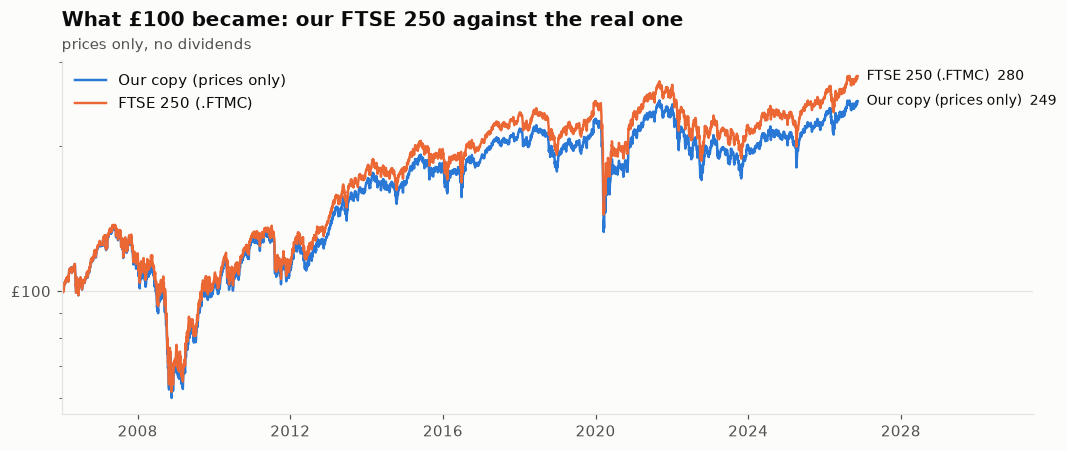

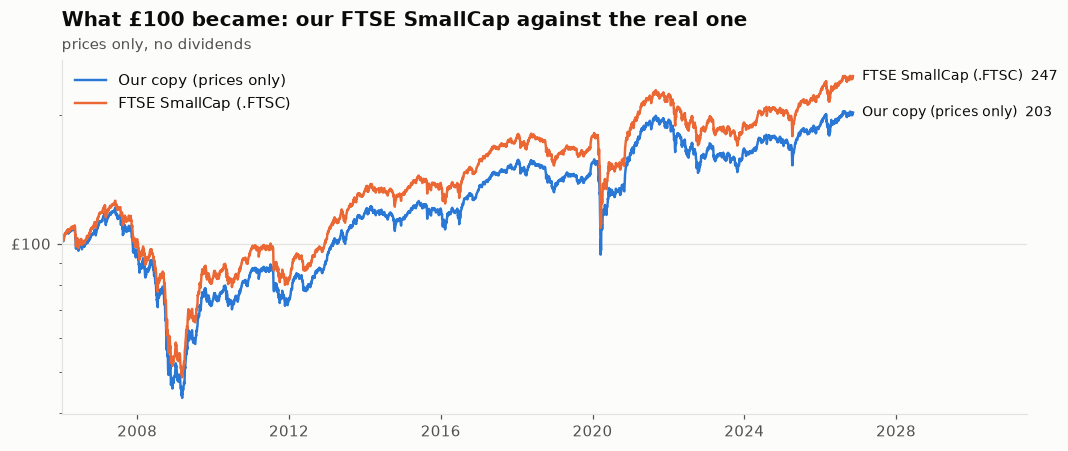

In [5]:
segment_returns = {}
for code, ric in SEGMENTS.items():
    members = allshare.segment == code
    ours = ix.cap_weighted(allshare.price_returns, allshare.market_cap, members)["return"]
    theirs = ix.vendor_returns(cache, ric, total=False, id_type="RIC")
    segment_returns[code] = (ours, theirs)
    fig = charts.growth(
        {"Our copy (prices only)": ours, f"{NAMES[code]} ({ric})": theirs},
        f"What £100 became: our {NAMES[code]} against the real one",
        subtitle="prices only, no dividends",
        symbol="£",
    )

## Summary statistics

One row per comparison. *Per year* is the compound annual growth rate (CAGR) over the whole period; *beta* the
slope of our daily returns on the official ones (1 = the same sensitivity to market moves).

In [6]:
pairs = {"All-Share + dividends vs .FTASXGBPT": (cap_tr["return"], ftas)}
pairs |= {f"{NAMES[code]} vs {ric}": segment_returns[code] for code, ric in SEGMENTS.items()}
summary = ix.tracking_summary(pairs)
display(summary.style.format(ix.TRACKING_FORMAT))

,days,ours_per_year,theirs_per_year,tracking_error,correlation,beta
All-Share + dividends vs .FTASXGBPT,"5,272",7.51%,7.20%,0.44%,0.9997,0.999
FTSE 100 vs .FTSE,"5,272",3.07%,3.15%,0.45%,0.9997,0.999
FTSE 250 vs .FTMC,"5,272",4.45%,5.05%,0.74%,0.9991,0.995
FTSE SmallCap vs .FTSC,"5,272",3.45%,4.42%,1.35%,0.9943,1.011


Tracking error year by year shows *when* the reconstruction is weakest - a data problem is usually confined to
a period.

In [7]:
by_year = ix.yearly_tracking_errors(pairs)
display(by_year.style.format("{:.2%}").background_gradient(cmap="Reds", vmin=0, vmax=0.05))

,All-Share + dividends vs .FTASXGBPT,FTSE 100 vs .FTSE,FTSE 250 vs .FTMC,FTSE SmallCap vs .FTSC
trade_date,,,,
2006,0.90%,0.38%,0.93%,1.85%
2007,0.35%,0.31%,1.36%,4.02%
2008,1.02%,1.16%,1.05%,2.44%
2009,0.86%,0.96%,1.92%,2.00%
2010,0.35%,0.36%,0.37%,0.85%
2011,0.31%,0.39%,0.57%,0.75%
2012,0.25%,0.22%,1.13%,0.55%
2013,0.18%,0.18%,0.48%,0.51%
2014,0.27%,0.31%,0.23%,0.83%


Calendar-year total returns of our All-Share and the official one.

,Our All-Share,FTSE All-Share TR,difference
trade_date,,,
2006,16.2%,15.5%,0.7%
2007,6.2%,5.3%,0.8%
2008,-28.1%,-29.9%,1.8%
2009,30.0%,30.1%,-0.1%
2010,14.6%,14.5%,0.1%
2011,-3.1%,-3.5%,0.4%
2012,12.4%,12.3%,0.1%
2013,21.1%,20.8%,0.3%
2014,1.7%,1.2%,0.5%


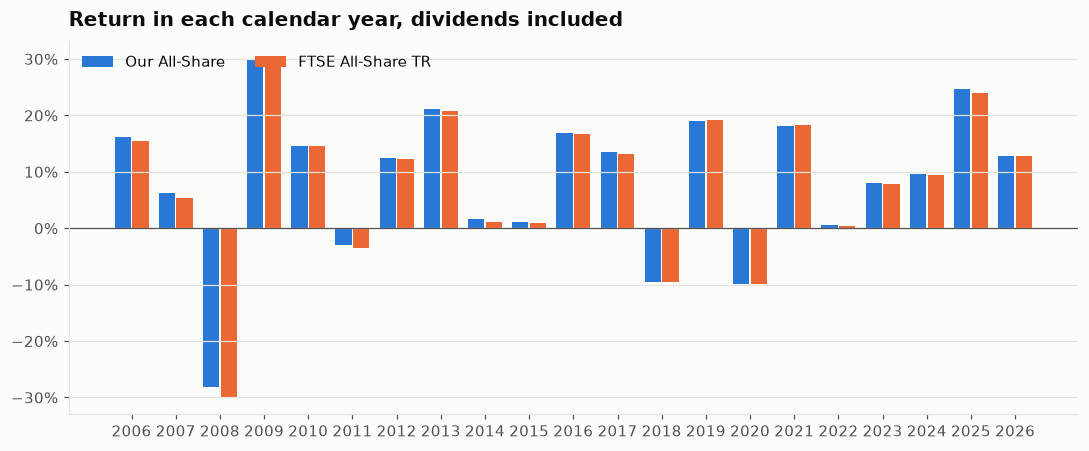

In [8]:
years = ix.calendar_years({"Our All-Share": cap_tr["return"], "FTSE All-Share TR": ftas})
fig = charts.yearly_bars(years, "Return in each calendar year, dividends included")
years["difference"] = years["Our All-Share"] - years["FTSE All-Share TR"]
display(years.style.format("{:.1%}"))

## Step 4 · Equal weight: the size effect

There is no official equal-weighted All-Share among our benchmarks, but the reconstruction makes one easy: every
member at weight $1/N$, reset each quarter end, a leaver's weight passed to the joiners. The UK market is far more
concentrated than the S&P 500's 500 names - an equal-weighted All-Share holds the ~175 SmallCap members at more weight
than the whole FTSE 100 - so the gap between the two lines is mostly the return of small UK companies relative to
large ones.

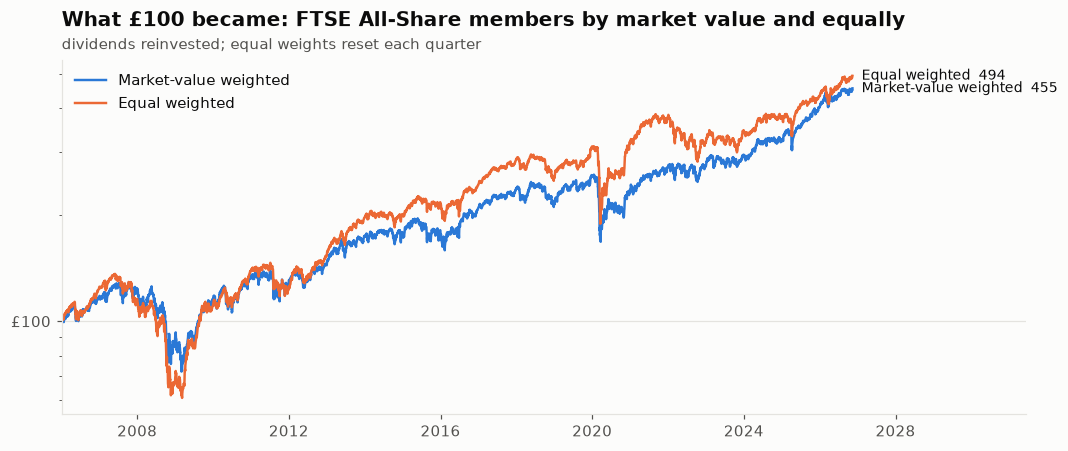

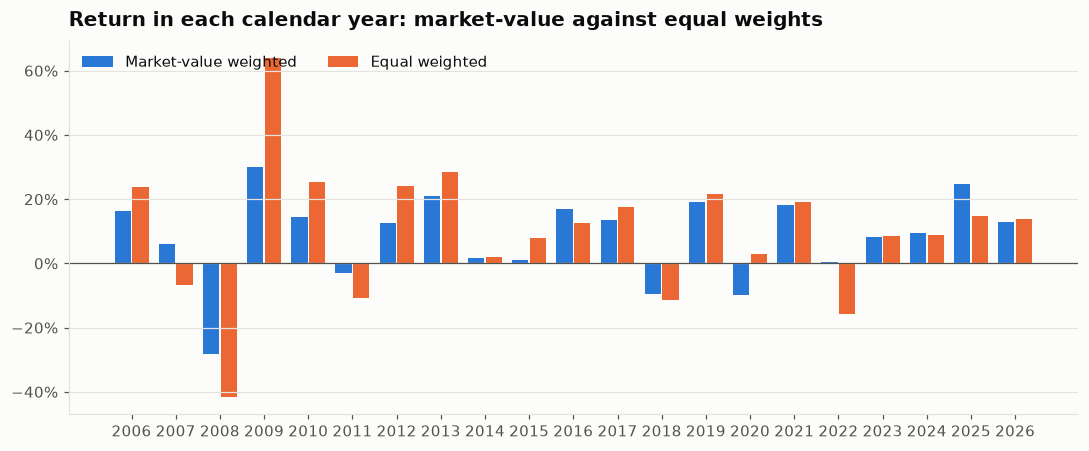

In [9]:
ew_tr = ix.equal_weighted(allshare.total_returns, allshare.members)
fig = charts.growth(
    {"Market-value weighted": cap_tr["return"], "Equal weighted": ew_tr["return"]},
    "What £100 became: FTSE All-Share members by market value and equally",
    subtitle="dividends reinvested; equal weights reset each quarter",
    symbol="£",
)
size = ix.calendar_years({"Market-value weighted": cap_tr["return"], "Equal weighted": ew_tr["return"]})
fig = charts.yearly_bars(size, "Return in each calendar year: market-value against equal weights")

## Step 5 · Without investment trusts: the research universe

The UK research universe (`FTSEAS`) leaves out investment trusts: their accounts describe a portfolio of other
companies' shares, so valuation ratios such as book-to-price or earnings yield mean something different for them. They
are a meaningful slice of the index by count (the cell prints how many of today's members are trusts) but a
small one by value, since most trusts are in the FTSE 250 and SmallCap.

LSEG also publishes the All-Share *ex investment trusts* (`.FTASXXMGBPT`), but its history here starts only in
September 2024 and its daily moves do not line up with the All-Share's (a correlation of 0.73 between the two, where
two versions of one market should be above 0.99), so the research universe is measured against the whole All-Share
(`.FTASXGBPT`) instead. The chart compares our All-Share with and without the trusts, to show what that costs.

127 of today's 526 members are investment trusts


,days,ours_per_year,theirs_per_year,tracking_error,correlation,beta
without vs with trusts,"5,272",0.07478,0.07512,0.003219,0.9998,1.005


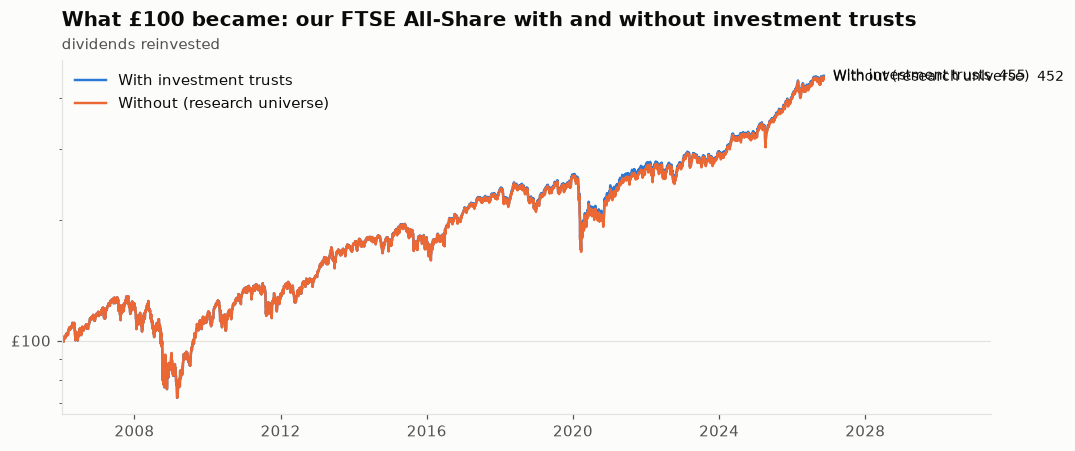

In [10]:
operating = ix.load_index_data(cache, "FTSEAS", START, TODAY, funds=False)
ex_trusts = ix.cap_weighted(operating.total_returns, operating.market_cap, operating.members)
trusts = int(allshare.members.iloc[-1].sum() - operating.members.iloc[-1].sum())
print(f"{trusts} of today's {int(allshare.members.iloc[-1].sum())} members are investment trusts")
fig = charts.growth(
    {"With investment trusts": cap_tr["return"], "Without (research universe)": ex_trusts["return"]},
    "What £100 became: our FTSE All-Share with and without investment trusts",
    subtitle="dividends reinvested",
    symbol="£",
)
display(pd.DataFrame([ix.tracking(ex_trusts["return"], cap_tr["return"])], index=["without vs with trusts"]))

## Findings and sources of tracking error

Results as of the last run (data to 12 November 2026, 5,272 trading days since January 2006, on the rebuilt database).

**The All-Share is reproduced closely.** Our total-return copy grows 7.51 % a year against the official index's
7.20 %, with a tracking error of 0.44 % a year and a daily correlation of 0.9997. Since 2010 every calendar year is
within about half a percentage point of the official return (the largest gaps, 2014, 2017 and 2025, are 0.5-0.6
points); the tracking error is at or below 0.3 % in most years. Spin-offs and rights issues are reinvested in the
parent (since 14 November 2026), as FTSE does: that lowered the tracking error in 2013 and 2019 (Prudential's demerger
of M&G) and narrowed the FTSE 100's shortfall from 0.18 to 0.08 points a year.

**The segments are harder, and the smaller the harder.** Prices only:

| | ours per year | official per year | tracking error | correlation |
|---|---|---|---|---|
| FTSE 100 | 3.07 % | 3.15 % | 0.45 % | 0.9997 |
| FTSE 250 | 4.45 % | 5.05 % | 0.74 % | 0.9991 |
| FTSE SmallCap | 3.45 % | 4.42 % | 1.35 % | 0.9943 |

Keeping each company in one segment at a time matters: with the replay's overlaps left in, the SmallCap's tracking
error was 2.9 % and its 2008 return 11.4 points below the official one (now 2.9 points); the FTSE 250's 2007 gap was
6.2 points (now 1.8). Today our segments hold 101, 251 and 174 listings - LSEG's lists of 100, 251 and 174, with one
FTSE 100 company that has two share lines.

Where the gap comes from:

* **Membership before 2010.** The year-by-year table shows the weakest years are 2006-2009, worst for the SmallCap
  (4.0 % tracking error in 2007). LSEG's joiner and leaver lists are least complete there: where neither a join nor a
  leave is recorded, the date of a move between segments is an estimate. The
  All-Share, the union of the three, is barely affected: a company moving between segments is still in it.
* **Members we cannot value.** Before 2009 we value 96.5-98.4 % of the members on an average day (99.3-99.8 % since
  2012). The ones we cannot value are left out; they are often companies in trouble, which may be why our All-Share is
  ahead of the official one in 2006-2008 (by 0.7, 0.8 and 1.8 points).
* **Price-only segments run below the official levels** (0.1 points a year for the FTSE 100, 0.6 for the 250, 1.0 for
  the SmallCap) while the total-return All-Share runs above. A likely cause is special dividends and capital returns:
  FTSE adjusts its price indices for them, so the level does not fall on the ex-date, whereas our price return does.
  The total-return All-Share, which counts them either way, shows no such shortfall.
* **Share counts and timing.** FTSE changes free-float factors and share counts at its quarterly reviews (effective
  after the third Friday of March, June, September and December) and moves members at a precise time; we use LSEG's
  monthly free-float counts and approximate every change to the day.
* **A consolidation LSEG lacks.** Wolseley (now Ferguson) consolidated its shares in April 2009 and its price jumps
  ×10.7 on 2 April. We have no share counts for it that month, so the market-value copies leave it out; the
  equal-weighted one does not, and the jump lifts its 2009 return from 63.0 % to 63.9 %.

**Equal weight is a bet on smaller companies.** Equal weighting earns 7.93 % a year against 7.51 % by market value,
but with a correlation of only 0.89 and a tracking error of 7.6 % a year - the UK market is far more concentrated than
the S&P 500. The difference is large in both directions: +33.9 points in 2009 and +12.7 in 2020's recovery, -13.5 in
2008, -16.2 in 2022 and -9.8 in 2025, when the largest companies led.

**Investment trusts barely move the index.** Leaving them out (the research universe) changes the return by 0.03
points a year (7.48 % against 7.51 %), with a tracking error of 0.32 %: trusts are many by count but small by value.

**For the UK backtests** this says the inputs are sound from 2010 and for the larger companies throughout; results
that depend on small companies in 2006-2009 deserve caution.
